<a href="https://colab.research.google.com/github/hrithikyeknath253-source/AI-ML_LAB_Submissions_HrithikYeknath/blob/main/AI_ML_Python_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **BFS Search Algorithm for AI/ML**

In [ ]:
from collections import deque
import builtins

graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['F'],
    'F': []
}

graph2 = {
    '1': ['2', '3'],
    '2': ['4', '5'],
    '3': ['6', '7'],
    '4': [],
    '5': [],
    '6': [],
    '7': []
}

def bfs(graph, start):
    if start not in graph:
        print("Invalid start node")
        return

    visited = []
    queue = deque([start])
    visited.append(start)

    while queue:
        node = queue.popleft()
        for neighbour in graph[node]:
            if neighbour not in visited:
                visited.append(neighbour)
                queue.append(neighbour)

    print("BFS Traversal:", visited)

choice = builtins.input("Choose graph (1 or 2): ")

if choice == "1":
    start = builtins.input("Enter start node (A-F): ").strip().upper()
    bfs(graph, start)
elif choice == "2":
    start = builtins.input("Enter start node (1-7): ").strip()
    bfs(graph2, start)
else:
    print("Invalid graph choice")

KeyboardInterrupt: Interrupted by user

# **DFS Search Algorithm for AI/ML**

In [ ]:
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['F'],
    'F': []
}

graph2 = {
    '1': ['2', '3'],
    '2': ['4', '5'],
    '3': ['6', '7'],
    '4': [],
    '5': [],
    '6': [],
    '7': []
}

def dfs(graph, start):
    visited = []
    stack = []

    stack.append(start)

    while stack:
        node = stack.pop()
        if node not in visited:
            visited.append(node)
            for neighbour in reversed(graph[node]):
                if neighbour not in visited:
                    stack.append(neighbour)

    print(visited)

choice = builtins.input("Choose graph (1 or 2): ")

if choice == "1":
    start = builtins.input("Enter start node: ").strip().upper()
    dfs(graph, start)
elif choice == "2":
    start = builtins.input("Enter start node: ").strip()
    dfs(graph2, start)
else:
    print("Invalid graph choice")

# **A Star Algorithm**

In [ ]:
graph_astar = {
    'A': {'B': 1, 'C': 4},
    'B': {'D': 2, 'E': 5},
    'C': {'F': 1},
    'D': {'G': 3},
    'E': {'G': 1},
    'F': {'G': 5},
    'G': {}
}

heuristic_astar = {
    'A': 7,
    'B': 6,
    'C': 4,
    'D': 2,
    'E': 1,
    'F': 3,
    'G': 0
}

open_list = []
start = 'A'
goal = 'G'

def astar(graph, heuristic, start, goal):
  open_list.append(start)
  cost = {start:0}
  while open_list:
    current = open_list[0]
    for node in open_list:
      if cost[node] + heuristic[node] < cost[current] + heuristic[current]:
        current = node
    if current == goal:
        print ("Goal node found!")
        return
    open_list.remove(current)
    for neighbour in graph[current]:
          if neighbour not in cost:
            cost[neighbour] = cost[current] + graph[current][neighbour]
            open_list.append(neighbour)
astar(graph_astar, heuristic_astar, start, goal)

# **Minimax Algorithm**

In [ ]:
board = [" " for _ in range(9)]

def display():
  print()
  print(board[0],"|") #Defining the board

In [ ]:
def display_board(board):
  print()
  print(board[0], '|', board[1], '|', board[2])
  print('---------')
  print(board[3], '|', board[4], '|', board[5])
  print('---------')
  print(board[6], '|', board[7], '|', board[8])
  print()

In [ ]:
def check_win(board, player):
  # Check rows
  for i in range(0, 9, 3):
    if board[i] == board[i+1] == board[i+2] == player:
      return True
  # Check columns
  for i in range(3):
    if board[i] == board[i+3] == board[i+6] == player:
      return True
  # Check diagonals
  if board[0] == board[4] == board[8] == player:
    return True
  if board[2] == board[4] == board[6] == player:
    return True
  return False

In [ ]:
def check_draw(board):
  return ' ' not in board and not (check_win(board, 'X') or check_win(board, 'O'))

In [ ]:
def minimax(board, depth, is_maximizing):
  if check_win(board, 'O'):  # AI wins
    return 1
  if check_win(board, 'X'):  # Player wins
    return -1
  if check_draw(board):
    return 0

  if is_maximizing:
    best_score = -float('inf')
    for i in range(9):
      if board[i] == ' ':
        board[i] = 'O'
        score = minimax(board, depth + 1, False)
        board[i] = ' ' # Undo the move
        best_score = max(score, best_score)
    return best_score
  else:
    best_score = float('inf')
    for i in range(9):
      if board[i] == ' ':
        board[i] = 'X'
        score = minimax(board, depth + 1, True)
        board[i] = ' ' # Undo the move
        best_score = min(score, best_score)
    return best_score

In [ ]:
def ai_move(board):
  best_score = -float('inf')
  best_move = -1
  for i in range(9):
    if board[i] == ' ':
      board[i] = 'O'
      score = minimax(board, 0, False)
      board[i] = ' ' # Undo the move
      if score > best_score:
        best_score = score
        best_move = i
  board[best_move] = 'O'

In [ ]:
def player_move(board):
  while True:
    try:
      move = int(builtins.input("Enter your move (0-8): "))
      if 0 <= move <= 8 and board[move] == ' ':
        board[move] = 'X'
        break
      else:
        print("Invalid move. Try again.")
    except ValueError:
      print("Invalid input. Please enter a number.")

In [ ]:
def play_game():
  board = [' ' for _ in range(9)]
  current_player = 'X' # X for human, O for AI

  print("Welcome to Tic Tac Toe!")
  display_board(board)

  while True:
    if current_player == 'X':
      player_move(board)
    else:
      print("AI's turn...")
      ai_move(board)

    display_board(board)

    if check_win(board, 'X'):
      print("You win!")
      break
    elif check_win(board, 'O'):
      print("AI wins!")
      break
    elif check_draw(board):
      print("It's a draw!")
      break

    current_player = 'O' if current_player == 'X' else 'X'

In [ ]:
import builtins
play_game()

# **Panda's Operations**

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"
df = pd.read_csv(url)
# Display Shape of Dataset
print(df.shape)

In [ ]:
df.info()

In [ ]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

In [ ]:
print(df.describe());

In [ ]:
print(df.isnull().sum())

In [ ]:
# df.duplicate().sum()
df['Age'] = df['Age'].fillna(df['Age'].median())
df.drop('Cabin', axis=1,inplace=True)
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode())
df.drop_duplicate(inplace=True)

In [ ]:
print(df['Age'].head())

In [ ]:
older_passengers = df[df['Age']>50]
print(older_passengers.head(10))

In [ ]:
females= df[df['Sex']=='female']
print(females.head(10))
females = df[df['Sex'] == 'female']
class_1_2 = df[df['Pclass'].isin([1,2])]

In [ ]:
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0,18,25,99],
    labels=['Children','Young Adults','Adult']
)
print(df[['Age', 'Age_Group']].head(10))

In [ ]:
average_age_gender = df.groupby('Sex')['Age'].mean()
print(average_age_gender)

# **MatPlotLib Linear graph**

In [ ]:
import matplotlib.pyplot as plt

# Sample linear data
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]

# Create a simple line plot
plt.figure(figsize=(6, 4))
plt.plot(x, y, marker='o', linestyle='-', color='g', label='y = 2x')

# Add labels and title
plt.title('Simple Linear Plot')
plt.xlabel('X Axis')
plt.ylabel('Y Axis')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

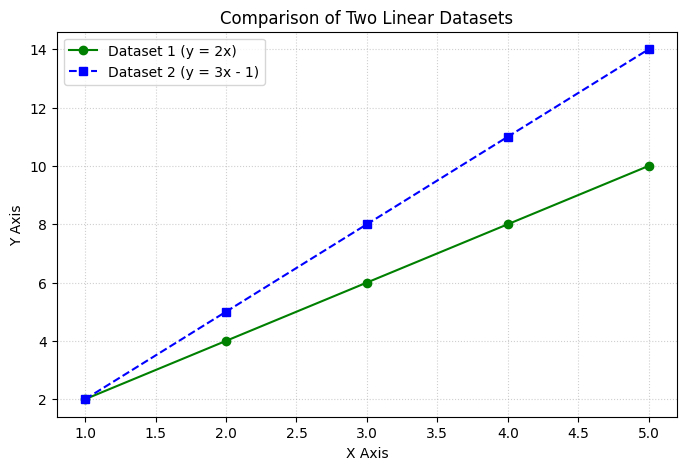

In [ ]:
import matplotlib.pyplot as plt

# Datasets
x1 = [1, 2, 3, 4, 5]
y1 = [2, 4, 6, 8, 10]

x2 = [1, 2, 3, 4, 5]
y2 = [2, 5, 8, 11, 14]

# Plotting both datasets
plt.figure(figsize=(8, 5))
plt.plot(x1, y1, marker='o', linestyle='-', color='g', label='Dataset 1 (y = 2x)')
plt.plot(x2, y2, marker='s', linestyle='--', color='b', label='Dataset 2 (y = 3x - 1)')

# Labels, Title and Legend
plt.title('Comparison of Two Linear Datasets')
plt.xlabel('X Axis')
plt.ylabel('Y Axis')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

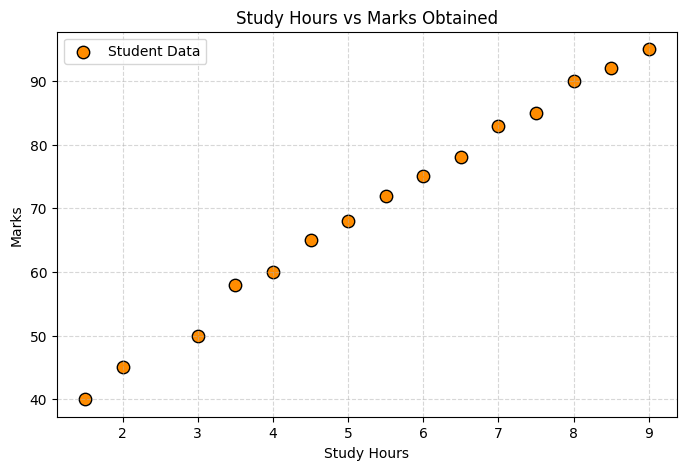

In [ ]:
import matplotlib.pyplot as plt

# Sample Data: Study Hours vs Marks
study_hours = [1.5, 2.0, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0]
marks = [40, 45, 50, 58, 60, 65, 68, 72, 75, 78, 83, 85, 90, 92, 95]

# Creating the scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(study_hours, marks, color='darkorange', marker='o', edgecolor='black', s=80, label='Student Data')

# Adding titles and labels
plt.title('Study Hours vs Marks Obtained')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

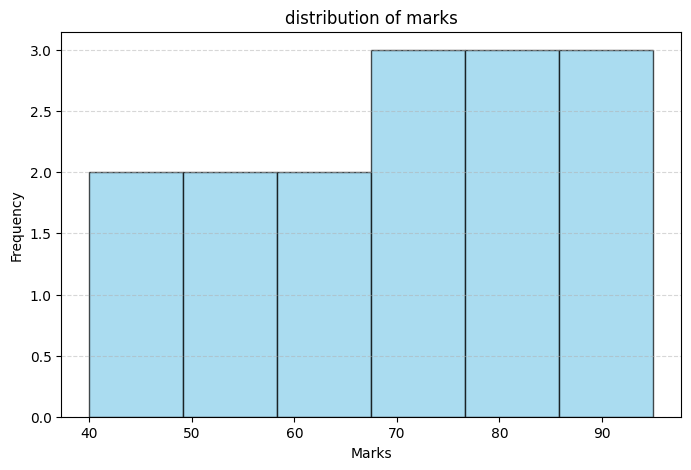

In [ ]:
import matplotlib.pyplot as plt

# Marks data from previous cell
marks = [40, 45, 50, 58, 60, 65, 68, 72, 75, 78, 83, 85, 90, 92, 95]

# Creating the histogram
plt.figure(figsize=(8, 5))
plt.hist(marks, bins=6, color='skyblue', edgecolor='black', alpha=0.7)

# Adding labels and title
plt.title('distribution of marks')
plt.xlabel('Marks')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Displaying the plot
plt.show()

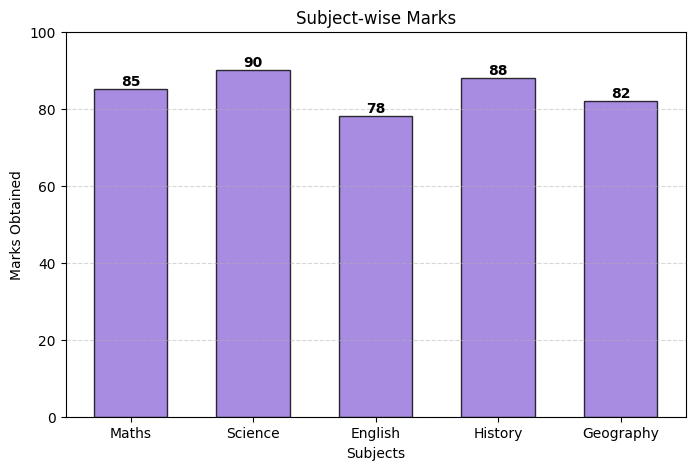

In [ ]:
import matplotlib.pyplot as plt

# Sample Data: Subjects and Marks
subjects = ['Maths', 'Science', 'English', 'History', 'Geography']
subject_marks = [85, 90, 78, 88, 82]

# Creating the bar chart
plt.figure(figsize=(8, 5))
plt.bar(subjects, subject_marks, color='mediumpurple', edgecolor='black', alpha=0.8, width=0.6)

# Adding labels and title
plt.title('Subject-wise Marks')
plt.xlabel('Subjects')
plt.ylabel('Marks Obtained')
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Displaying the values on top of each bar
for i, v in enumerate(subject_marks):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold')

# Displaying the plot
plt.show()

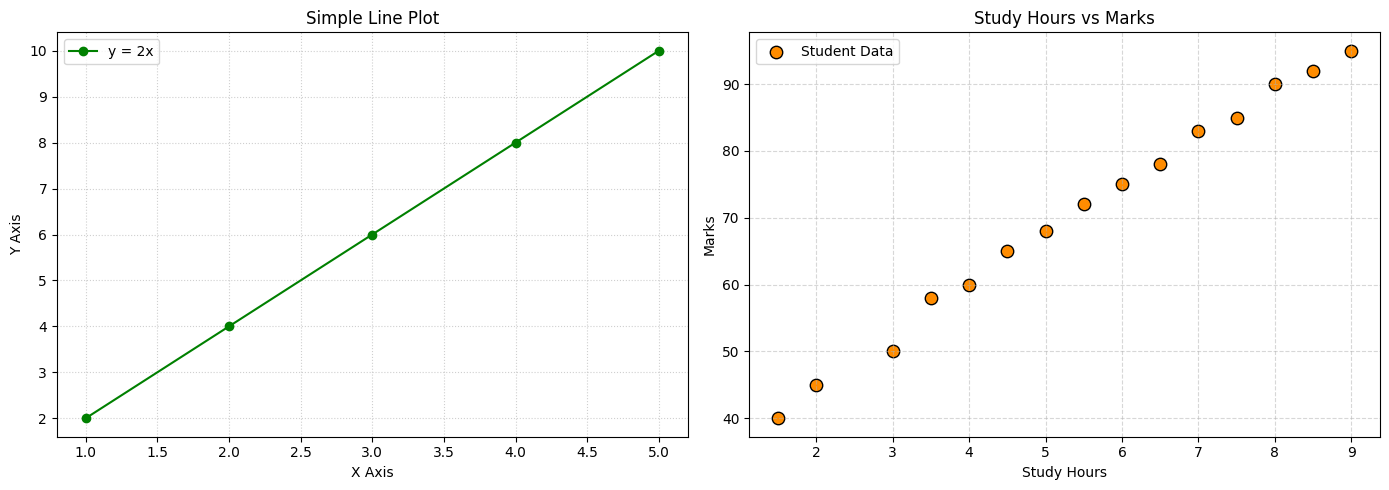

In [ ]:
import matplotlib.pyplot as plt

# Datasets
x_line = [1, 2, 3, 4, 5]
y_line = [2, 4, 6, 8, 10]

study_hours = [1.5, 2.0, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0]
marks = [40, 45, 50, 58, 60, 65, 68, 72, 75, 78, 83, 85, 90, 92, 95]

# Creating subplots using plt.subplot
plt.figure(figsize=(14, 5))

# Left plot: Line Plot
plt.subplot(1, 2, 1)
plt.plot(x_line, y_line, marker='o', linestyle='-', color='g', label='y = 2x')
plt.title('Simple Line Plot')
plt.xlabel('X Axis')
plt.ylabel('Y Axis')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Right plot: Scatter Plot
plt.subplot(1, 2, 2)
plt.scatter(study_hours, marks, color='darkorange', marker='o', edgecolor='black', s=80, label='Student Data')
plt.title('Study Hours vs Marks')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

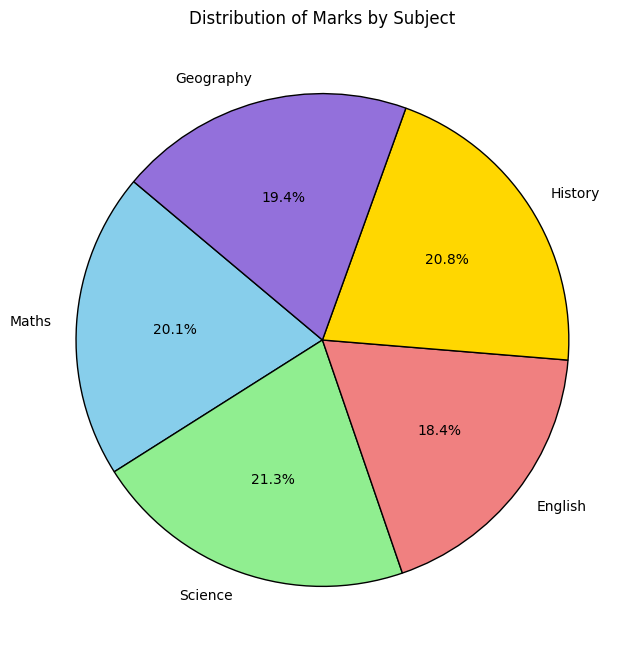

In [ ]:
import matplotlib.pyplot as plt

# Data: Subjects and Marks from previous steps
subjects = ['Maths', 'Science', 'English', 'History', 'Geography']
subject_marks = [85, 90, 78, 88, 82]

# Creating the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    subject_marks,
    labels=subjects,
    autopct='%1.1f%%',
    startangle=140,
    colors=['skyblue', 'lightgreen', 'lightcoral', 'gold', 'mediumpurple'],
    wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'antialiased': True}
)

# Adding a title
plt.title('Distribution of Marks by Subject')

# Displaying the plot
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Create the dataset
data = {
    'Student': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O'],
    'Study_Hours': [2, 3, 4, 5, 6, 7, 8, 9, 3, 4, 6, 7, 8, 2, 5],
    'Attendance': [65, 70, 75, 80, 82, 85, 90, 92, 68, 72, 78, 88, 91, 60, 76],
    'Marks': [45, 50, 58, 65, 70, 75, 82, 88, 48, 55, 68, 78, 85, 40, 62],
    'Assignments': [5, 6, 7, 8, 8, 9, 10, 10, 5, 6, 8, 9, 10, 4, 7],
    'Gender': ['F', 'M', 'F', 'M', 'F', 'M', 'F', 'M', 'F', 'M', 'F', 'M', 'F', 'M', 'F']
}

df = pd.DataFrame(data)
display(df)

,Student,Study_Hours,Attendance,Marks,Assignments,Gender
0,A,2,65,45,5,F
1,B,3,70,50,6,M
2,C,4,75,58,7,F
3,D,5,80,65,8,M
4,E,6,82,70,8,F
5,F,7,85,75,9,M
6,G,8,90,82,10,F
7,H,9,92,88,10,M
8,I,3,68,48,5,F
9,J,4,72,55,6,M


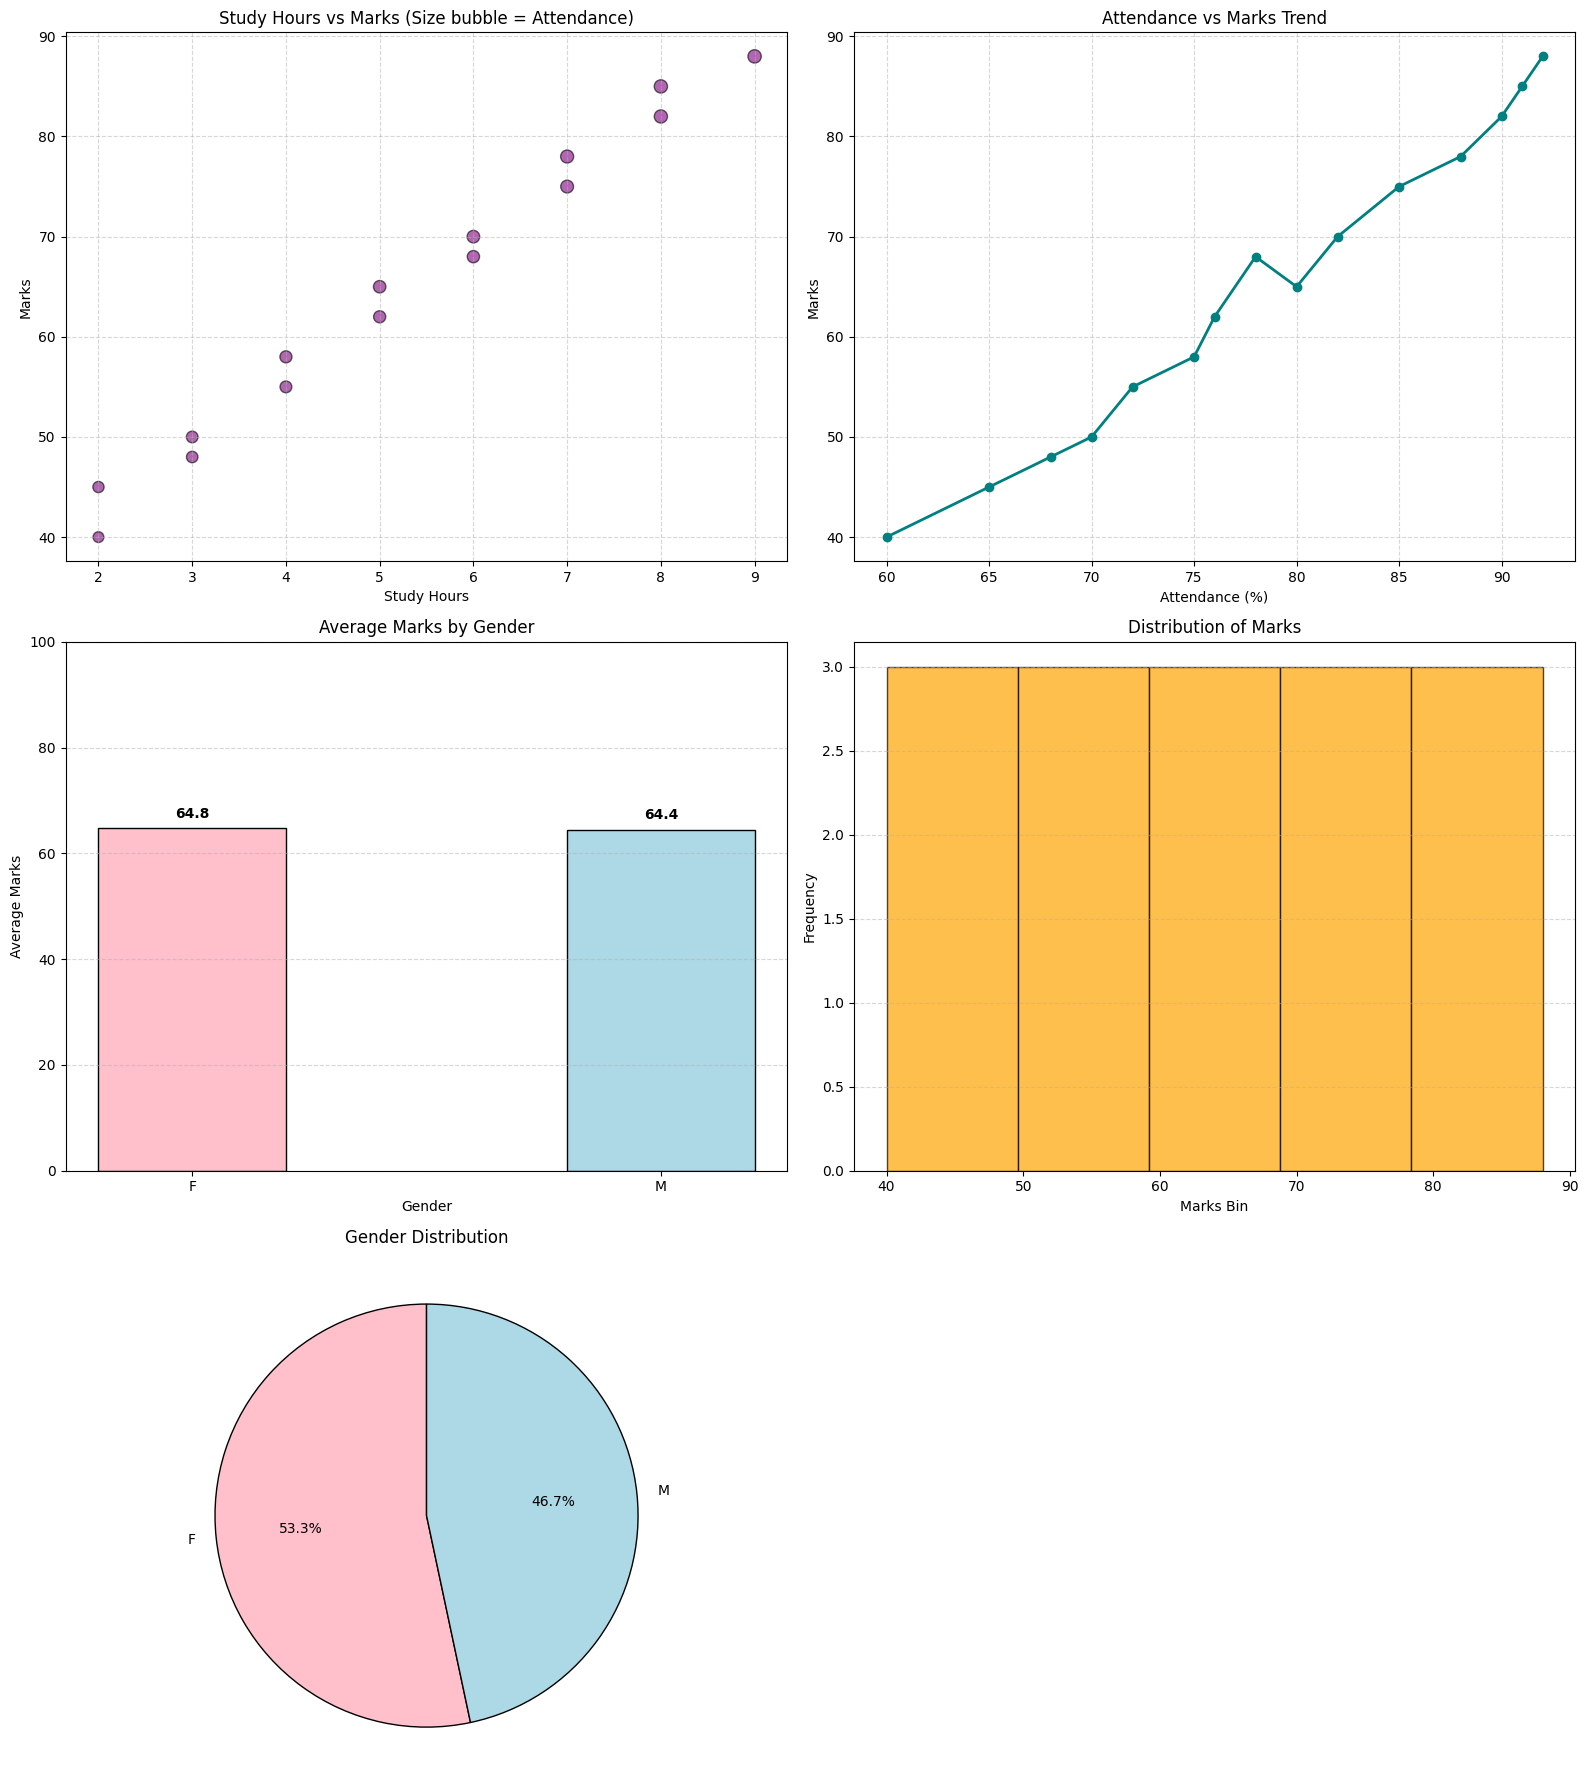

In [ ]:
# Create subplots to show all forms of applicable graphs
fig = plt.figure(figsize=(16, 18))

# 1. Scatter Plot: Study Hours vs Marks
plt.subplot(3, 2, 1)
plt.scatter(df['Study_Hours'], df['Marks'], s=df['Attendance'], c='purple', alpha=0.6, edgecolors='black')
plt.title('Study Hours vs Marks (Size bubble = Attendance)')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.grid(True, linestyle='--', alpha=0.5)

# 2. Line Plot: Attendance vs Marks (sorted to show trend)
df_sorted = df.sort_values(by='Attendance')
plt.subplot(3, 2, 2)
plt.plot(df_sorted['Attendance'], df_sorted['Marks'], marker='o', color='teal', linestyle='-', linewidth=2)
plt.title('Attendance vs Marks Trend')
plt.xlabel('Attendance (%)')
plt.ylabel('Marks')
plt.grid(True, linestyle='--', alpha=0.5)

# 3. Bar Chart: Average Marks by Gender
gender_marks = df.groupby('Gender')['Marks'].mean().reset_index()
plt.subplot(3, 2, 3)
plt.bar(gender_marks['Gender'], gender_marks['Marks'], color=['pink', 'lightblue'], edgecolor='black', width=0.4)
plt.title('Average Marks by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Marks')
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)
for idx, val in enumerate(gender_marks['Marks']):
    plt.text(idx, val + 2, f"{val:.1f}", ha='center', fontweight='bold')

# 4. Histogram: Distribution of Marks
plt.subplot(3, 2, 4)
plt.hist(df['Marks'], bins=5, color='orange', edgecolor='black', alpha=0.7)
plt.title('Distribution of Marks')
plt.xlabel('Marks Bin')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Pie Chart: Proportion of Gender in Class
gender_counts = df['Gender'].value_counts()
plt.subplot(3, 2, 5)
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90, colors=['pink', 'lightblue'], wedgeprops={'edgecolor': 'black'})
plt.title('Gender Distribution')

plt.tight_layout()
plt.show()

# **Experiment No 6**

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"
titanic_df = pd.read_csv(url)

print("--- Missing Values Before Preprocessing ---")
print(titanic_df.isnull().sum())

titanic_df['Age'] = titanic_df['Age'].fillna(titanic_df['Age'].median())
titanic_df['Embarked'] = titanic_df['Embarked'].fillna(titanic_df['Embarked'].mode()[0])
if 'Cabin' in titanic_df.columns:
    titanic_df.drop('Cabin', axis=1, inplace=True)

le_sex = LabelEncoder()
titanic_df['Sex_Encoded'] = le_sex.fit_transform(titanic_df['Sex'])

le_embarked = LabelEncoder()
titanic_df['Embarked_Encoded'] = le_embarked.fit_transform(titanic_df['Embarked'])

scaler = MinMaxScaler()
num_cols = ['Age', 'Fare']
titanic_df[num_cols] = scaler.fit_transform(titanic_df[num_cols])

print("\n--- Missing Values After Preprocessing ---")
print(titanic_df.isnull().sum())

print("\n--- Preprocessed Dataset Sample ---")
display(titanic_df[['PassengerId', 'Survived', 'Pclass', 'Sex_Encoded', 'Age', 'Fare', 'Embarked_Encoded']].head())

--- Missing Values Before Preprocessing ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

--- Missing Values After Preprocessing ---
PassengerId         0
Survived            0
Pclass              0
Name                0
Sex                 0
Age                 0
SibSp               0
Parch               0
Ticket              0
Fare                0
Embarked            0
Sex_Encoded         0
Embarked_Encoded    0
dtype: int64

--- Preprocessed Dataset Sample ---


,PassengerId,Survived,Pclass,Sex_Encoded,Age,Fare,Embarked_Encoded
0,1,0,3,1,0.271174,0.014151,2
1,2,1,1,0,0.472229,0.139136,0
2,3,1,3,0,0.321438,0.015469,2
3,4,1,1,0,0.434531,0.103644,2
4,5,0,3,1,0.434531,0.015713,2
